<a href="https://colab.research.google.com/github/pauloricardopg/RedesNeuraisArtificiais-PPCOM/blob/main/Dataset_IMDB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análise de Sentimento — Dataset IMDB

In [1]:
!curl -O https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz
!tar -xf aclImdb_v1.tar.gz
!pip install transformers -qq

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 80.2M  100 80.2M    0     0  4619k      0  0:00:17  0:00:17 --:--:-- 4505k


In [2]:
import pathlib

test_dir = pathlib.Path("aclImdb/test")
test_texts = []
test_labels = []

# neg = 0, pos = 1 (mesma convenção do dataset original)
for label, category in enumerate(["neg", "pos"]):
    for file_path in sorted((test_dir / category).glob("*.txt")):
        test_texts.append(file_path.read_text(encoding="utf-8"))
        test_labels.append(label)

print(f"Total de reviews carregados: {len(test_texts)}")
print(f"Exemplo (label={test_labels[0]}):\n{test_texts[0][:300]}...")

Total de reviews carregados: 25000
Exemplo (label=0):
Once again Mr. Costner has dragged out a movie for far longer than necessary. Aside from the terrific sea rescue sequences, of which there are very few I just did not care about any of the characters. Most of us have ghosts in the closet, and Costner's character are realized early on, and then forgo...


In [3]:
import torch
from transformers import pipeline

use_gpu = torch.cuda.is_available()
print(f"Rodando em: {'GPU (' + torch.cuda.get_device_name(0) + ')' if use_gpu else 'CPU'}")

pipe = pipeline(
    "text-classification",
    model="lvwerra/distilbert-imdb",
    device=0 if use_gpu else -1,
    torch_dtype=torch.float16 if use_gpu else torch.float32
)

Rodando em: GPU (Tesla T4)


config.json:   0%|          | 0.00/735 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  268MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

... (2 outputs left out)

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [4]:
import time
from tqdm.auto import tqdm

batch_size = 64
results = []

start = time.time()
for i in tqdm(range(0, len(test_texts), batch_size), desc="Analisando IMDB"):
    batch = test_texts[i:i + batch_size]
    results.extend(pipe(batch, truncation=True, max_length=512))

elapsed = time.time() - start
y_pred = [1 if r["label"] == "POSITIVE" else 0 for r in results]
print(f"\nTempo total (25.000 reviews): {elapsed:.2f} segundos")

Analisando IMDB:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Tempo total (25.000 reviews): 200.05 segundos


Acurácia no conjunto de teste: 0.9280 (92.80%)

              precision    recall  f1-score   support

    NEGATIVE       0.93      0.93      0.93     12500
    POSITIVE       0.93      0.93      0.93     12500

    accuracy                           0.93     25000
   macro avg       0.93      0.93      0.93     25000
weighted avg       0.93      0.93      0.93     25000



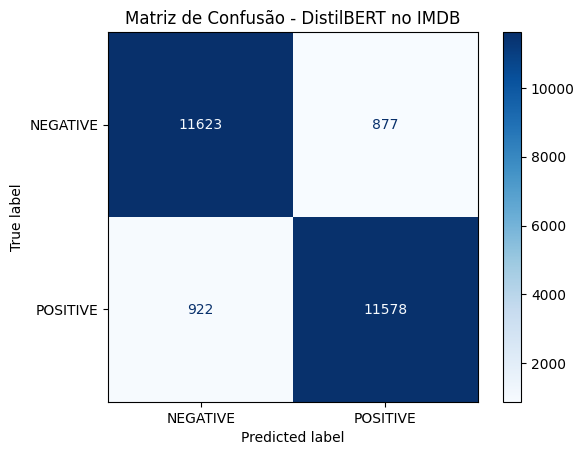

In [5]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

acc = accuracy_score(test_labels, y_pred)
print(f"Acurácia no conjunto de teste: {acc:.4f} ({acc*100:.2f}%)\n")
print(classification_report(test_labels, y_pred, target_names=["NEGATIVE", "POSITIVE"]))

cm = confusion_matrix(test_labels, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["NEGATIVE", "POSITIVE"])
disp.plot(cmap="Blues")
plt.title("Matriz de Confusão - DistilBERT no IMDB")
plt.show()

In [6]:
import random

# Mostra 3 acertos e 3 erros aleatórios
acertos = [i for i in range(len(test_labels)) if y_pred[i] == test_labels[i]]
erros   = [i for i in range(len(test_labels)) if y_pred[i] != test_labels[i]]

nomes = {0: "NEGATIVE", 1: "POSITIVE"}

print("=== EXEMPLOS DE ACERTOS ===")
for idx in random.sample(acertos, 3):
    print(f"[Real: {nomes[test_labels[idx]]} | Previsto: {results[idx]['label']} ({results[idx]['score']:.2%})]")
    print(test_texts[idx][:220].replace("<br />", " "), "...\n")

print("=== EXEMPLOS DE ERROS ===")
for idx in random.sample(erros, 3):
    print(f"[Real: {nomes[test_labels[idx]]} | Previsto: {results[idx]['label']} ({results[idx]['score']:.2%})]")
    print(test_texts[idx][:220].replace("<br />", " "), "...\n")

=== EXEMPLOS DE ACERTOS ===
[Real: NEGATIVE | Previsto: NEGATIVE (99.64%)]
If you like stupid jokes and a terribly predictable storyline, then perhaps this movie is for you. Courtney Thorne-Smith, Jack Warden, and several other members of the supporting cast actually have talent, but it was com ...

[Real: POSITIVE | Previsto: POSITIVE (99.03%)]
This is a romantic, albeit cheesy movie that is one of my all time favorites. It is one of the many CLASSICS of the 80's genre like "Pretty in Pink" or "Some kind of Wonderful".  Nic plays the traditional punk  ...

[Real: POSITIVE | Previsto: POSITIVE (99.38%)]
I have to confess that I slept in the cinema while watching the first Asterix movie... but this one is simply FANTASTIC! It is really funny and it leaves the first one miles away. It has enumerous gags and funny situatio ...

=== EXEMPLOS DE ERROS ===
[Real: POSITIVE | Previsto: NEGATIVE (81.42%)]
It's too bad iameracing wants to deny the reality of Faulkner's and Clarence Brown's purpo